In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/DIGIPRENEURSHIP/coffee_shop_sales_raw.csv")
df.head()

,transaction_id,date,time,product,category,unit_price,quantity,discount_rate,discount_amount,total_amount,payment_method,order_type
0,TRX01142,2026-01-01,11:44,Cheesecake,Food,23000,3,0.05,3450,65550,QRIS,Dine In
1,TRX01756,2026-01-01,13:53,Es Kopi Susu,Coffee,18000,1,0.00,0,18000,Debit,Dine In
2,TRX00683,2026-01-01,14:06,Cappuccino,Coffee,20000,1,0.00,0,20000,QRIS,Dine In
3,TRX02236,2026-01-01,14:31,French Fries,Food,20000,1,0.00,0,20000,E-Wallet,Delivery
4,TRX00272,2026-01-01,14:34,Es Kopi Susu,Coffee,18000,1,0.00,0,18000,QRIS,Dine In


In [ ]:
print(df.shape)
df.info()

(2505, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2505 entries, 0 to 2504
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   transaction_id   2505 non-null   object 
 1   date             2505 non-null   object 
 2   time             2505 non-null   object 
 3   product          2505 non-null   object 
 4   category         2505 non-null   object 
 5   unit_price       2505 non-null   int64  
 6   quantity         2505 non-null   int64  
 7   discount_rate    2505 non-null   float64
 8   discount_amount  2505 non-null   int64  
 9   total_amount     2505 non-null   int64  
 10  payment_method   2493 non-null   object 
 11  order_type       2505 non-null   object 
dtypes: float64(1), int64(4), object(7)
memory usage: 235.0+ KB


In [ ]:
df.isna().sum()
print("Baris dobel:", df.duplicated().sum())
print("ID transaksi dobel:", df.transaction_id.duplicated().sum())
df[df.transaction_id.duplicated(keep=False)].sort_values("transaction_id")

Baris dobel: 5
ID transaksi dobel: 5


,transaction_id,date,time,product,category,unit_price,quantity,discount_rate,discount_amount,total_amount,payment_method,order_type
130,TRX00515,2026-01-10,19:34,Croissant,Food,18000,1,0.05,900,17100,E-Wallet,Take Away
2504,TRX00515,2026-01-10,19:34,Croissant,Food,18000,1,0.05,900,17100,E-Wallet,Take Away
312,TRX01152,2026-01-24,09:52,Chocolate,Non-Coffee,20000,2,0.05,2000,38000,QRIS,Take Away
2501,TRX01152,2026-01-24,09:52,Chocolate,Non-Coffee,20000,2,0.05,2000,38000,QRIS,Take Away
462,TRX01483,2026-02-03,19:09,Cappuccino,Coffee,20000,1,0.00,0,20000,E-Wallet,Dine In
2500,TRX01483,2026-02-03,19:09,Cappuccino,Coffee,20000,1,0.00,0,20000,E-Wallet,Dine In
931,TRX01992,2026-03-10,13:55,Cappuccino,Coffee,20000,1,0.00,0,20000,Cash,Take Away
2503,TRX01992,2026-03-10,13:55,Cappuccino,Coffee,20000,1,0.00,0,20000,Cash,Take Away
1840,TRX02247,2026-05-13,08:20,Matcha Latte,Non-Coffee,22000,1,0.00,0,22000,QRIS,Take Away
2502,TRX02247,2026-05-13,08:20,Matcha Latte,Non-Coffee,22000,1,0.00,0,22000,QRIS,Take Away


In [ ]:
# 1. Hapus transaksi dobel (simpan yang pertama)
df = df.drop_duplicates(subset="transaction_id").copy()

# 2. Isi metode pembayaran yang kosong
df["payment_method"] = df["payment_method"].fillna("Unknown")

# 3. Ubah kolom date jadi tipe tanggal
df["date"] = pd.to_datetime(df["date"])

# 4. Buat kolom baru: jam, bulan, nama hari
df["hour"] = df["time"].str[:2].astype(int)
df["month"] = df["date"].dt.to_period("M").astype(str)
df["day_name"] = df["date"].dt.day_name()

print("Ukuran data bersih:", df.shape)

Ukuran data bersih: (2500, 15)


In [ ]:
hitung = (df.unit_price * df.quantity * (1 - df.discount_rate)).round()
print("Total yang tidak cocok:", (hitung != df.total_amount).sum())

Total yang tidak cocok: 0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [ ]:
print(f"Total pendapatan    : Rp {df.total_amount.sum():,.0f}")
print(f"Jumlah transaksi    : {len(df):,}")
print(f"Rata-rata/transaksi : Rp {df.total_amount.mean():,.0f}")
print(f"Total diskon        : Rp {df.discount_amount.sum():,.0f}")

Total pendapatan    : Rp 77,328,250
Jumlah transaksi    : 2,500
Rata-rata/transaksi : Rp 30,931
Total diskon        : Rp 1,408,750


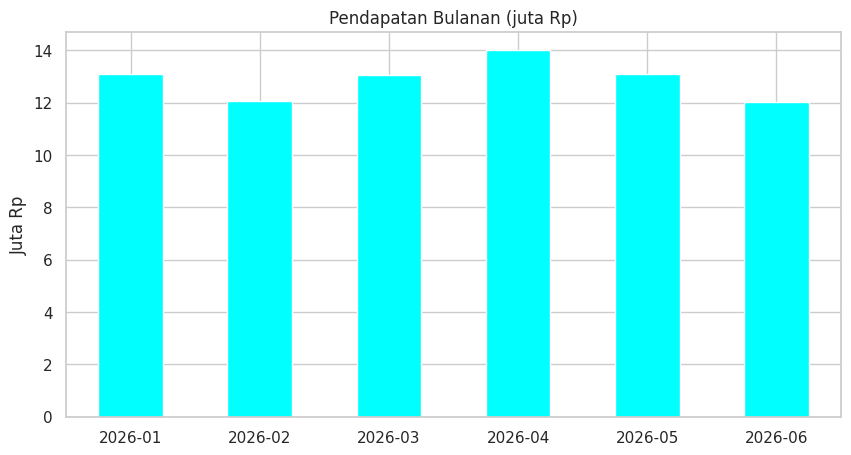

In [ ]:
bulan = df.groupby("month").total_amount.sum() / 1e6

ax = bulan.plot(kind="bar", color="#00FFFF")
ax.set_title("Pendapatan Bulanan (juta Rp)")
ax.set_xlabel("")
ax.set_ylabel("Juta Rp")
plt.xticks(rotation=0)
plt.show()

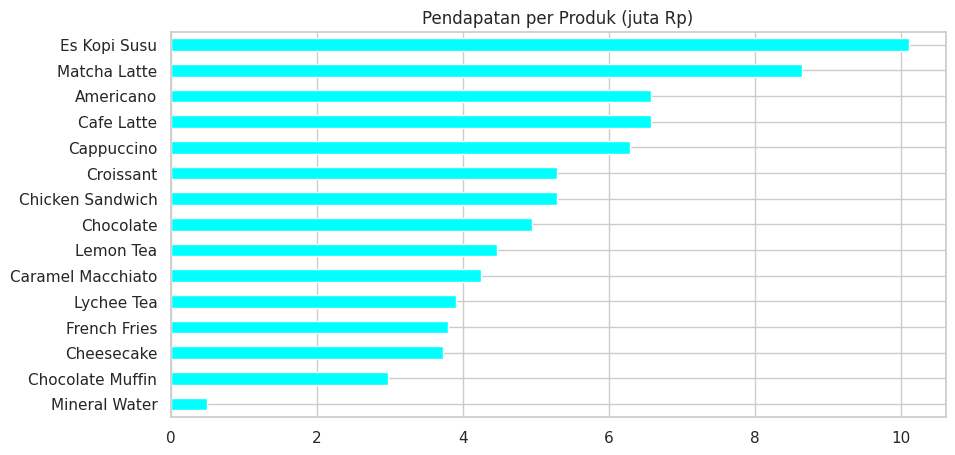

In [ ]:
produk = df.groupby("product").total_amount.sum().sort_values() / 1e6

ax = produk.plot(kind="barh", color="#00FFFF")
ax.set_title("Pendapatan per Produk (juta Rp)")
ax.set_ylabel("")
plt.show()

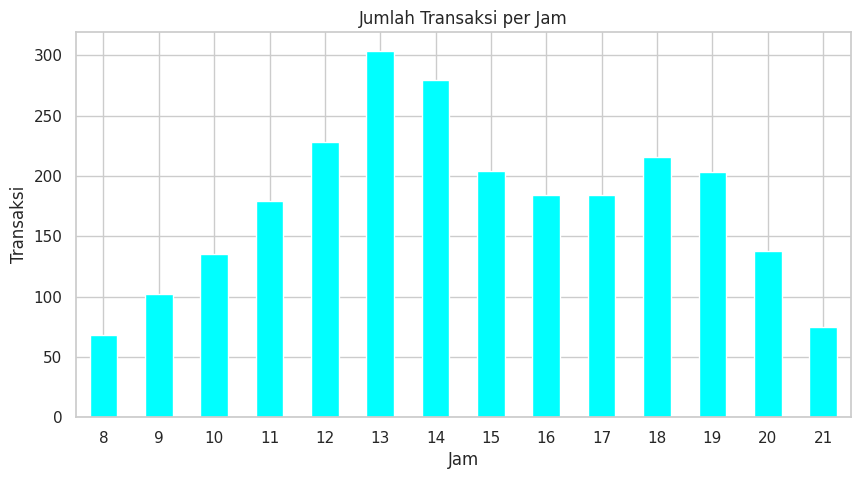

In [ ]:
jam = df.groupby("hour").size()

ax = jam.plot(kind="bar", color="#00FFFF")
ax.set_title("Jumlah Transaksi per Jam")
ax.set_xlabel("Jam")
ax.set_ylabel("Transaksi")
plt.xticks(rotation=0)
plt.show()

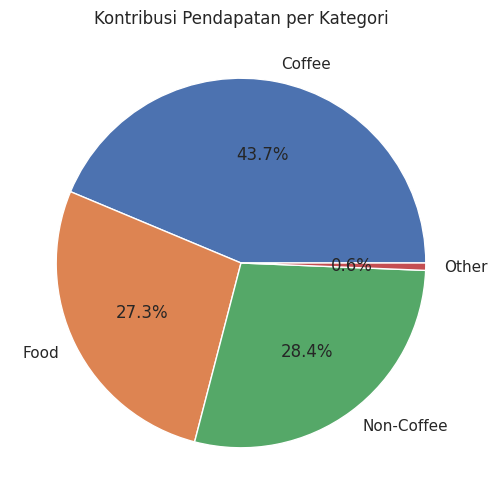

In [ ]:
kat = df.groupby("category").total_amount.sum()

kat.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Kontribusi Pendapatan per Kategori")
plt.ylabel("")
plt.show()